<h1 align="center">📈 Sales Prediction Using Python</h1>
<h3 align="center">Predicting product sales from advertising spend on TV, Radio and Newspaper</h3>

<p align="center"><b>Oasis Infobyte Internship Program (OIBSIP) · Data Science · Task 5</b></p>

---

| | |
|---|---|
| **Author** | Rini Ramadhan Naim |
| **Track** | Data Science |
| **Task** | Task 5 — Sales Prediction Using Python |
| **Dataset** | `Advertising.csv` (200 markets: TV, Radio, Newspaper spend and Sales) |
| **Tech stack** | Python · pandas · scikit-learn · matplotlib · seaborn · Jupyter Notebook |

---

## 🎯 Objective

Build **regression models** that predict product **sales** from the advertising spend on three media channels
(**TV**, **Radio**, **Newspaper**), compare the models, and find out **which channel has the highest impact on sales**.

> **Regression vs classification:** in Task 1 the answer was a category (a species). Here the answer is a
> **number** (sales), so the models are evaluated with **MAE, RMSE and R²** instead of accuracy.

## 🗺️ Table of contents

1. [Setup](#1.-Setup)
2. [Load the dataset](#2.-Load-the-dataset)
3. [Exploratory data analysis (EDA)](#3.-Exploratory-data-analysis-(EDA))
4. [Visualisations](#4.-Visualisations)
5. [Train/test split](#5.-Train/test-split)
6. [Baseline: Linear Regression](#6.-Baseline:-Linear-Regression)
7. [Additional models](#7.-Additional-models)
8. [Model comparison and best model](#8.-Model-comparison-and-best-model)
9. [Residual analysis](#9.-Residual-analysis)
10. [Which channel has the highest impact?](#10.-Which-channel-has-the-highest-impact?)
11. [Conclusion](#11.-Conclusion)

---
## 1. Setup

> **What happens here:** import the libraries, fix a random seed, set a plot style and print the library versions.

In [1]:
# Standard libraries
import sys
import warnings
warnings.filterwarnings("ignore")

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Global settings
RANDOM_STATE = 42                       # fixed seed so results can be repeated
sns.set_theme(style="whitegrid", context="notebook")

# Library versions
print(f"Python  : {sys.version.split()[0]}")
print(f"pandas  : {pd.__version__}")
print(f"numpy   : {np.__version__}")
print(f"sklearn : {sklearn.__version__}")

Python  : 3.12.3
pandas  : 3.0.6
numpy   : 2.5.4
sklearn : 1.9.1


---
## 2. Load the dataset

> **What happens here:** read the classic **Advertising** dataset. The file `Advertising.csv` must be in the
> **same folder as this notebook**. The first column is only a row number, so it is used as the index.

| Column | Meaning |
|---|---|
| `TV` | Advertising spend on TV |
| `radio` | Advertising spend on radio |
| `newspaper` | Advertising spend on newspapers |
| `sales` | **Target:** product sales |

*In the original ISLR version of this dataset, spend is in thousands of dollars and sales in thousands of units.
The file itself has no units, so the numbers are best read as relative amounts.*

In [2]:
# Read the CSV; the first column is just a row number, so it becomes the index
df = pd.read_csv("Advertising.csv", index_col=0)

FEATURES = ["TV", "radio", "newspaper"]
TARGET = "sales"

df.head()

,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


---
## 3. Exploratory data analysis (EDA)

> **What happens here:** check the shape, data types, missing values, duplicates and summary statistics.

In [3]:
# Shape and data types
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print(df.dtypes)

Shape: 200 rows x 4 columns

TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object


In [4]:
# Missing values (null check) and duplicated rows
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicated rows: {df.duplicated().sum()}")

Missing values per column:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Duplicated rows: 0


In [5]:
# Descriptive statistics
df.describe().round(2)

,TV,radio,newspaper,sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


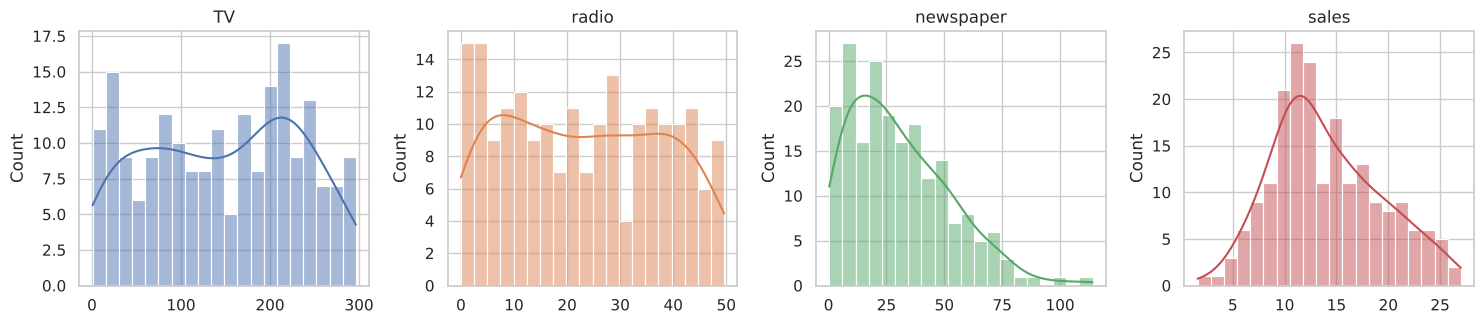

In [6]:
# Distribution of every column
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, col, color in zip(axes, df.columns, ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]):
    sns.histplot(df[col], bins=20, kde=True, color=color, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 📝 EDA notes

- ✅ The dataset has **200 rows** and **4 numeric columns** (3 features and 1 target).
- ✅ There are **no missing values** and **no duplicated rows**, so no cleaning is needed.
- ℹ️ The three spend columns are on **different ranges**: TV goes up to about 296, radio up to about 50 and
  newspaper up to about 114. This matters later, when the channels are compared fairly.
- ℹ️ `newspaper` is **right-skewed** and has a few large values (the maximum is far above the 75th percentile).
  These are kept, because they are valid budgets and the dataset is small.
- ✅ `sales` is spread fairly evenly, from about 1.6 to 27.

---
## 4. Visualisations

> **What happens here:** look at how each channel relates to sales, and how the channels relate to each other.

### 4.1 Pairplot of all features

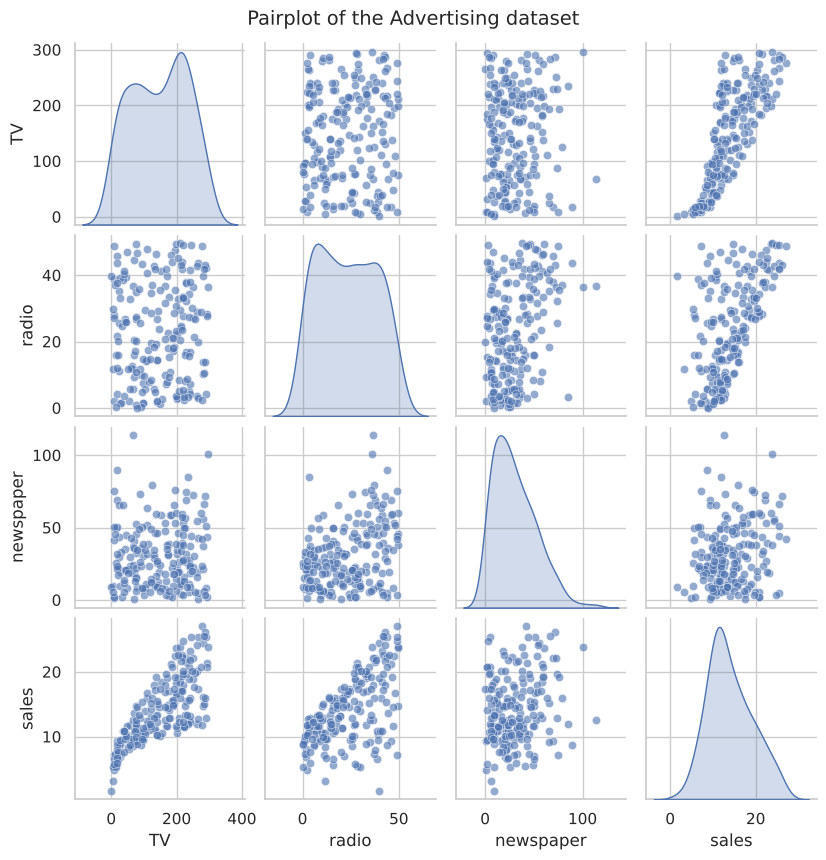

In [7]:
# Scatter plot of every pair of columns (diagonal = distribution of one column)
g = sns.pairplot(df, diag_kind="kde", corner=False, height=2.1,
                 plot_kws={"alpha": 0.6, "color": "#4C72B0"})
g.figure.suptitle("Pairplot of the Advertising dataset", y=1.02, fontsize=14)
plt.show()

### 4.2 Individual scatter plots: sales against each channel

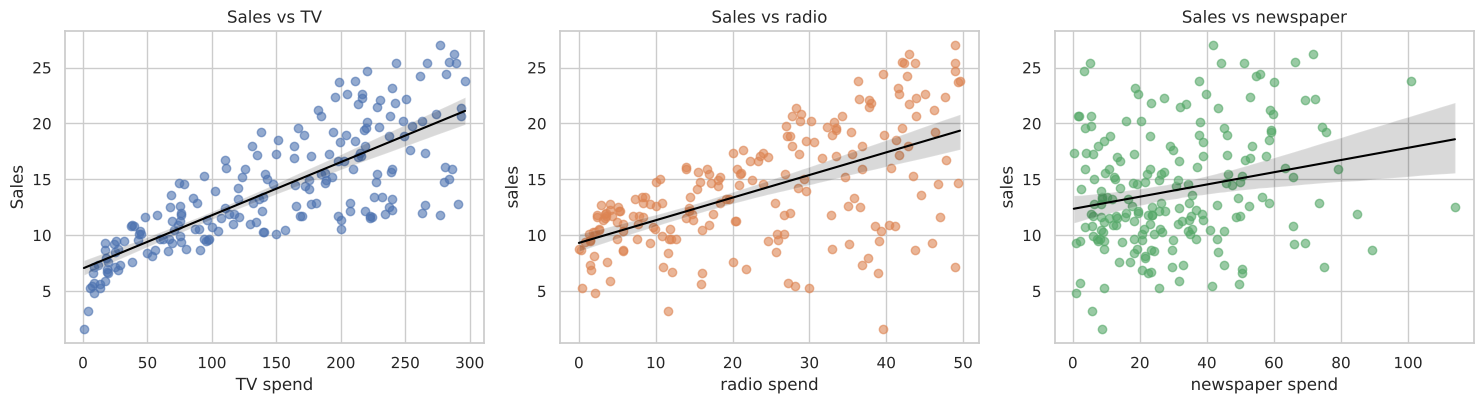

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, color in zip(axes, FEATURES, ["#4C72B0", "#DD8452", "#55A868"]):
    sns.regplot(data=df, x=col, y=TARGET, ax=ax, color=color,
                scatter_kws={"alpha": 0.6}, line_kws={"color": "black", "linewidth": 1.5})
    ax.set_title(f"Sales vs {col}")
    ax.set_xlabel(f"{col} spend")
axes[0].set_ylabel("Sales")
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

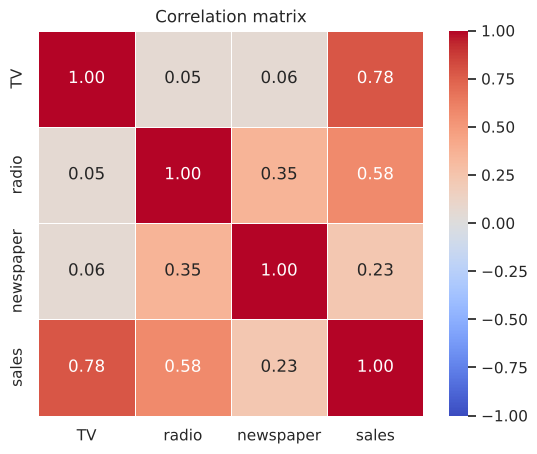

In [9]:
plt.figure(figsize=(6.5, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix")
plt.show()

### 📝 What the plots show

| Channel | Relationship with sales | Correlation |
|---|---|---|
| **TV** | Strong and clear upward trend. The points spread out more at high TV spend. | about **0.78** |
| **Radio** | Positive trend, but with much more scatter. | about **0.58** |
| **Newspaper** | Very weak trend, points scattered almost everywhere. | about **0.23** |

**Observations**

1. **TV** is the channel most strongly related to sales.
2. The three spend columns are **almost unrelated to TV** (correlation about 0.06), which is good for modelling.
3. **Radio and newspaper are moderately correlated (about 0.35).** So newspaper may look useful partly because it
   is spent together with radio. Its real effect has to be checked **with the other channels held fixed**,
   which a regression model does (see [Section 10](#10.-Which-channel-has-the-highest-impact?)).
4. The TV scatter plot is slightly **curved and fans out**, a hint that a straight line may not be enough.

---
## 5. Train/test split

> **What happens here:** keep **80%** of the data for training and **20%** for testing. The test data is not
> used for learning, so it shows how the model behaves on new markets. There is no `stratify` here, because the
> target is a number, not a category.

In [10]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}    y_test : {y_test.shape}")

X_train: (160, 3)   y_train: (160,)
X_test : (40, 3)    y_test : (40,)


---
## 6. Baseline: Linear Regression

> **What happens here:** train the simplest model first, a **Linear Regression**. It becomes the **baseline**
> that the other models must beat.

Linear Regression learns one equation:

`sales = intercept + a × TV + b × radio + c × newspaper`

**Metrics used (for a numeric target)**

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | Average size of the error | Lower |
| **RMSE** | Like MAE, but big errors count more | Lower |
| **R²** | Share of the variation in sales explained by the model (1.0 = perfect) | Higher |

In [11]:
# Helper that evaluates a fitted model on the test set
def evaluate(name, model):
    pred = model.predict(X_test)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    }

# Train the baseline
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

baseline = evaluate("Linear Regression (baseline)", lin_reg)
print(f"MAE  : {baseline['MAE']:.3f}")
print(f"RMSE : {baseline['RMSE']:.3f}")
print(f"R2   : {baseline['R2']:.4f}")

MAE  : 1.461
RMSE : 1.782
R2   : 0.8994


---
## 7. Additional models

> **What happens here:** train two more models (the task asks for at least one).

| Model | Idea in one line |
|---|---|
| **Polynomial Regression (degree 2)** | Still a linear model, but it also uses squared terms and **combinations** of channels (for example TV × radio), so it can bend and capture teamwork between channels |
| **Random Forest Regressor** | Averages many decision trees, so it can follow curves without an equation |

Polynomial features are **standardised** inside a pipeline, so the scaler learns only from the training data.

In [12]:
models = {
    "Linear Regression (baseline)": lin_reg,
    "Polynomial Regression (degree 2)": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
}

# Train the two additional models (the baseline is already trained)
for name, model in models.items():
    if name != "Linear Regression (baseline)":
        model.fit(X_train, y_train)
        print(f"Trained: {name}")

Trained: Polynomial Regression (degree 2)
Trained: Random Forest


---
## 8. Model comparison and best model

> **What happens here:** compare all models with **MAE, RMSE and R²** on the test set. As in Task 1, a small
> test set (only 40 markets) can be lucky, so **5-fold cross-validation** (R²) is added as a steadier check.

In [13]:
# Test-set metrics
rows = [evaluate(name, model) for name, model in models.items()]
results = pd.DataFrame(rows).set_index("Model")

# 5-fold cross-validated R2 on all 200 rows
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = {name: cross_val_score(model, X, y, cv=cv, scoring="r2")
         for name, model in models.items()}
results["CV R2 (mean)"] = [cv_r2[n].mean() for n in results.index]
results["CV R2 (std)"] = [cv_r2[n].std() for n in results.index]

results = results.sort_values("CV R2 (mean)", ascending=False)
results.round(4)

,MAE,RMSE,R2,CV R2 (mean),CV R2 (std)
Model,,,,,
Polynomial Regression (degree 2),0.5262,0.6426,0.9869,0.9834,0.0077
Random Forest,0.6139,0.7406,0.9826,0.9805,0.0048
Linear Regression (baseline),1.4608,1.7816,0.8994,0.8827,0.0395


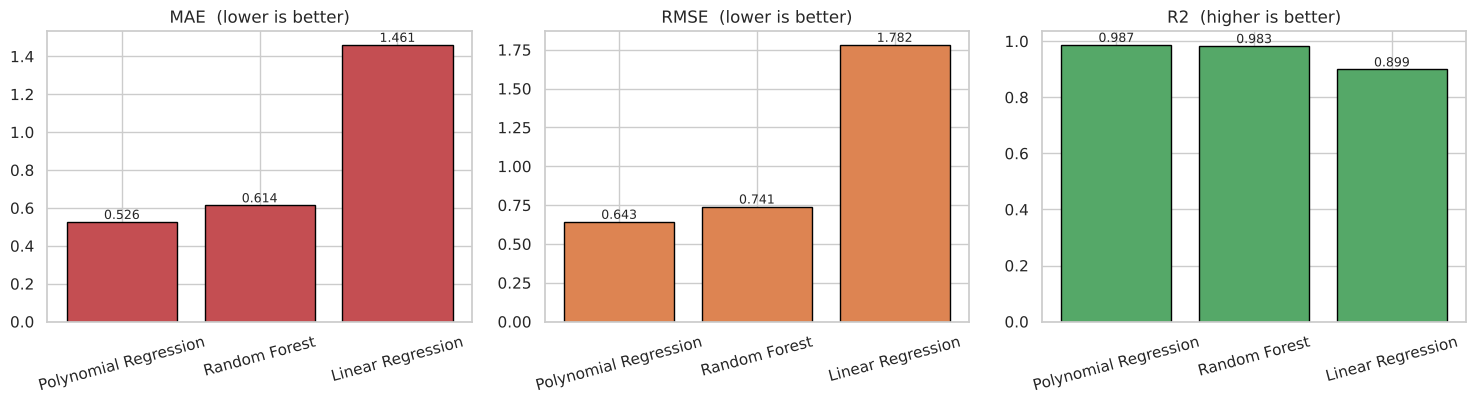

In [14]:
# Bar charts of the three test metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
short = [n.replace(" (baseline)", "").replace(" (degree 2)", "") for n in results.index]
for ax, metric, color in zip(axes, ["MAE", "RMSE", "R2"], ["#C44E52", "#DD8452", "#55A868"]):
    ax.bar(short, results[metric], color=color, edgecolor="black")
    ax.set_title(metric + ("  (lower is better)" if metric != "R2" else "  (higher is better)"))
    ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(results[metric]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

In [15]:
# Declare the best model: highest cross-validated R2
best_name = results.index[0]
best_model = models[best_name]

print(f"🏆 Best model: {best_name}")
print(f"   Cross-validated R2 : {results.loc[best_name, 'CV R2 (mean)']:.4f} (+/- {results.loc[best_name, 'CV R2 (std)']:.4f})")
print(f"   Test R2            : {results.loc[best_name, 'R2']:.4f}")
print(f"   Test MAE / RMSE    : {results.loc[best_name, 'MAE']:.3f} / {results.loc[best_name, 'RMSE']:.3f}")

🏆 Best model: Polynomial Regression (degree 2)
   Cross-validated R2 : 0.9834 (+/- 0.0077)
   Test R2            : 0.9869
   Test MAE / RMSE    : 0.526 / 0.643


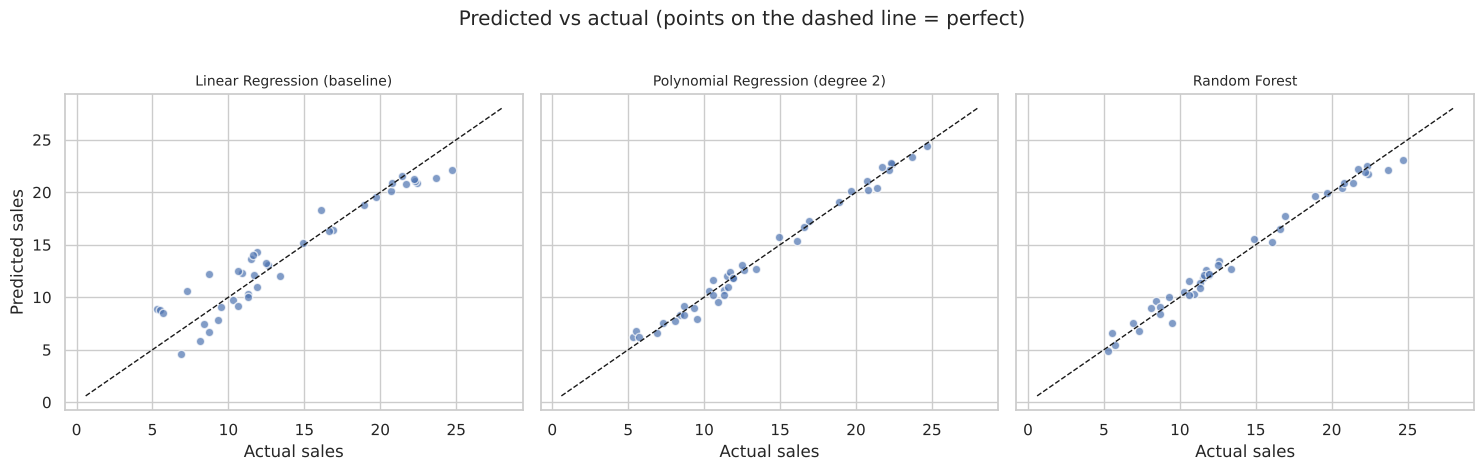

In [16]:
# Predicted vs actual sales on the test set for every model
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
lims = [y.min() - 1, y.max() + 1]
for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    ax.scatter(y_test, pred, alpha=0.7, edgecolor="white", color="#4C72B0")
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Actual sales")
axes[0].set_ylabel("Predicted sales")
plt.suptitle("Predicted vs actual (points on the dashed line = perfect)", y=1.02)
plt.tight_layout()
plt.show()

### 🏆 Best model and justification

The best model is the one printed above, chosen by the **highest cross-validated R²**.

**What the table shows**

- The **linear baseline** explains about **90%** of the variation in sales. Good, but its errors are the largest.
- **Polynomial Regression** and **Random Forest** both explain about **98%** and cut the error to **less than half**
  of the baseline (RMSE about 0.6 to 0.7 against 1.8).
- Polynomial Regression and Random Forest are **very close** to each other, and their gap is smaller than the
  spread across folds. So the top spot is a narrow call, not a clear victory.

**Why do the flexible models win?** The linear model assumes every extra unit of spend adds the same amount of sales.
The real data is not like that: the TV plot is curved, and the channels seem to **work better together**.
[Section 10](#10.-Which-channel-has-the-highest-impact?) shows this inside the polynomial model.

---
## 9. Residual analysis

> **What happens here:** a **residual** is `actual sales - predicted sales`. If a model is well suited to the data,
> its residuals look **random**, centred on zero, with no pattern. A visible pattern means the model misses
> something **systematic**.
>
> The plots below show the **best model** and, for comparison, the **linear baseline**.

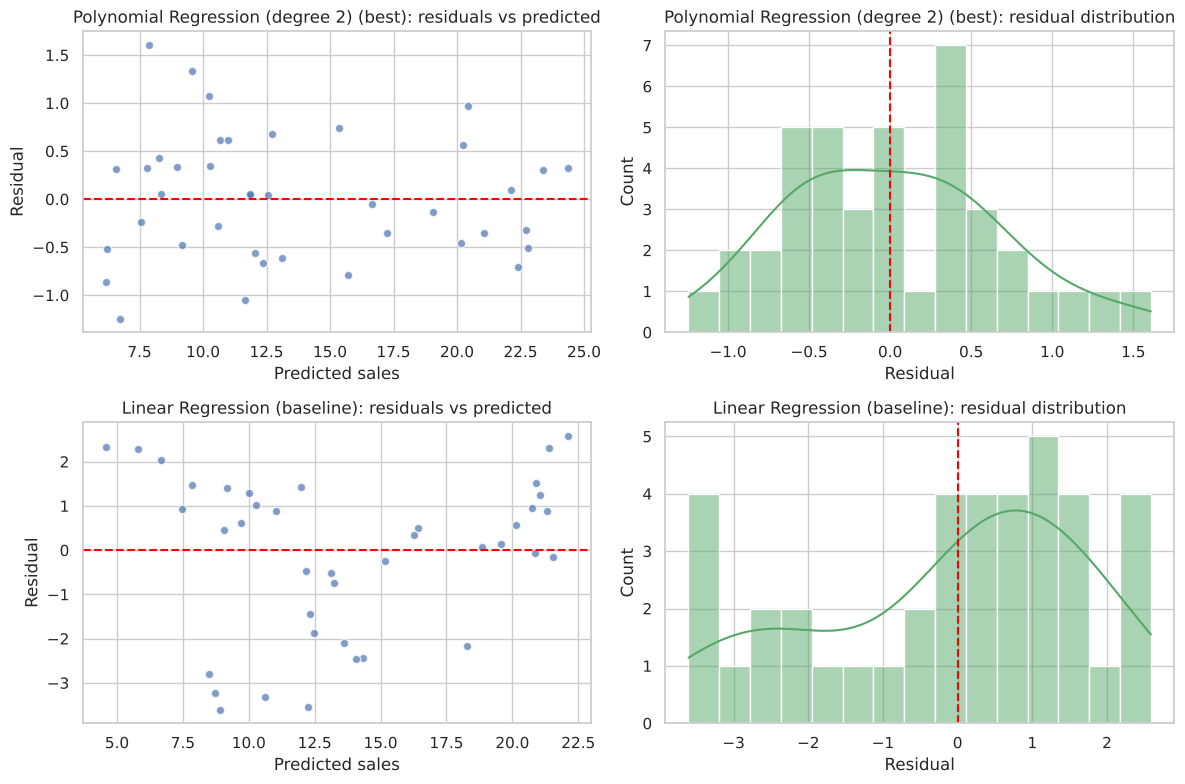

Polynomial Regression (degree 2)   mean residual = +0.017   std = 0.651
Linear baseline                    mean residual = -0.098   std = 1.802


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (title, model) in enumerate([(best_name + " (best)", best_model),
                                       ("Linear Regression (baseline)", lin_reg)]):
    pred = model.predict(X_test)
    resid = y_test - pred

    # Residuals against predicted values
    axes[row, 0].scatter(pred, resid, alpha=0.7, edgecolor="white", color="#4C72B0")
    axes[row, 0].axhline(0, color="red", linestyle="--")
    axes[row, 0].set_title(f"{title}: residuals vs predicted")
    axes[row, 0].set_xlabel("Predicted sales")
    axes[row, 0].set_ylabel("Residual")

    # Distribution of the residuals
    sns.histplot(resid, bins=15, kde=True, color="#55A868", ax=axes[row, 1])
    axes[row, 1].axvline(0, color="red", linestyle="--")
    axes[row, 1].set_title(f"{title}: residual distribution")
    axes[row, 1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

for title, model in [(best_name, best_model), ("Linear baseline", lin_reg)]:
    resid = y_test - model.predict(X_test)
    print(f"{title:<34} mean residual = {resid.mean():+.3f}   std = {resid.std():.3f}")

### 📝 Are the errors random or systematic?

**Best model (Polynomial Regression):** the residuals are **scattered around zero** with **no clear curve and no funnel
shape**. Most errors stay within about ±1, the mean residual is almost exactly zero (about +0.02) and the histogram is
roughly bell-shaped, with only a small tail on the positive side. This looks like **random noise**, which is what a
well-suited model should leave behind.

**Linear baseline:** the residuals show a clear **curved (U-shaped) pattern**. The errors are **positive** when predicted
sales are low or high, and **negative** in the middle, and they reach about ±3.5. That is a **systematic** error: a
straight line cannot follow the real, curved relationship, so it **over-predicts** in the middle range and
**under-predicts** at the two ends.

**Conclusion:** the pattern in the baseline's residuals is the reason the flexible models are better. They remove most
of that pattern.

*Note: there are only 40 test points, so this judgement is visual and should be read with care.*

---
## 10. Which channel has the highest impact?

> **What happens here:** answer the key question in three ways, since each one shows a different side of "impact".
> **TV, radio and newspaper are on different scales**, so a fair comparison needs care.

### 10.1 Linear Regression coefficients

In [18]:
# Raw coefficient = extra sales for 1 extra unit of spend on that channel
# Standardised coefficient = extra sales for a 1-standard-deviation increase (fair across channels)
coef = pd.DataFrame({
    "Raw coefficient (per 1 unit of spend)": lin_reg.coef_,
    "Standardised coefficient (per 1 std)": lin_reg.coef_ * X_train.std().values,
}, index=FEATURES)
print(f"Intercept: {lin_reg.intercept_:.3f}")
coef.round(4)

Intercept: 2.979


,Raw coefficient (per 1 unit of spend),Standardised coefficient (per 1 std)
TV,0.0447,3.7760
radio,0.1892,2.8011
newspaper,0.0028,0.0562


### 10.2 Feature importance (Random Forest) and permutation importance (best model)

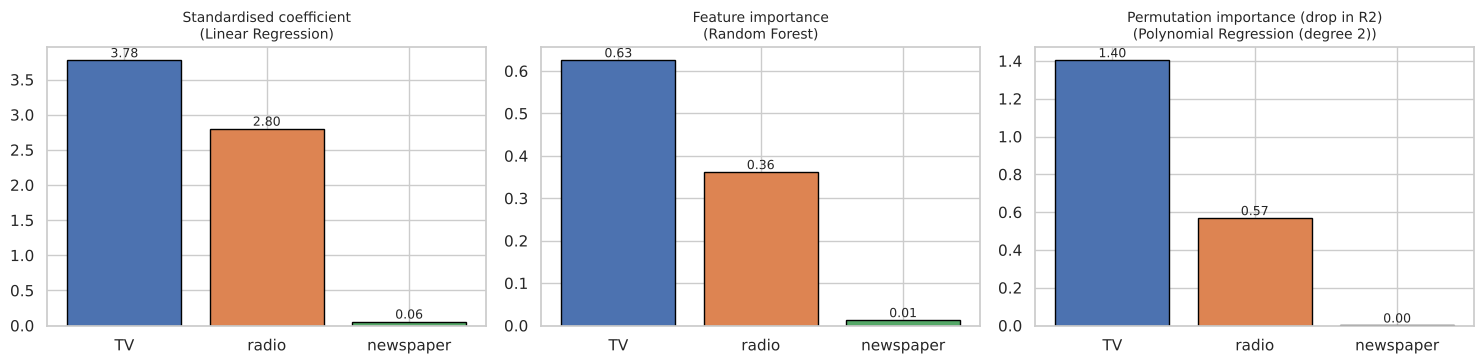

In [19]:
# Random Forest importance: how much each channel is used to reduce error
rf_importance = pd.Series(models["Random Forest"].feature_importances_, index=FEATURES)

# Permutation importance on the test set: how much the best model gets worse when one channel is shuffled
perm = permutation_importance(best_model, X_test, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring="r2")
perm_importance = pd.Series(perm.importances_mean, index=FEATURES)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
colors = ["#4C72B0", "#DD8452", "#55A868"]
for ax, series, title in zip(
        axes,
        [coef.iloc[:, 1], rf_importance, perm_importance],
        ["Standardised coefficient\n(Linear Regression)",
         "Feature importance\n(Random Forest)",
         "Permutation importance (drop in R2)\n(" + best_name + ")"]):
    ax.bar(FEATURES, series.values, color=colors, edgecolor="black")
    ax.set_title(title, fontsize=10)
    for i, v in enumerate(series.values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

### 10.3 Teamwork between channels (inside the polynomial model)

In [20]:
# Largest terms of the Polynomial Regression (features are standardised, so sizes are comparable)
poly = models["Polynomial Regression (degree 2)"]
term_names = poly.named_steps["polynomialfeatures"].get_feature_names_out(FEATURES)
terms = pd.Series(poly.named_steps["linearregression"].coef_, index=term_names)
terms.reindex(terms.abs().sort_values(ascending=False).index).head(6).round(3)

TV              4.480
TV radio        3.679
TV^2           -2.855
TV newspaper   -0.345
radio           0.252
newspaper       0.215
dtype: float64

### 📝 Interpretation

| Question | Answer from the results |
|---|---|
| **Which channel drives sales the most overall?** | **TV.** It has the largest standardised coefficient (about 3.8 against 2.8 for radio), the largest Random Forest importance (about 62%) and the largest permutation importance. |
| **Which channel gives the most sales per unit of spend?** | **Radio.** Its raw coefficient is about 0.19 per unit of spend, against about 0.045 for TV. A little radio spend seems to go further than the same amount of TV. |
| **And newspaper?** | **Almost nothing.** Its coefficient is close to zero (about 0.003) and its importance is about 1% or less. Its correlation with sales (0.23) came mostly from being spent together with radio. |
| **Do channels work together?** | **Yes, it seems so.** In the polynomial model the **TV × radio** term is one of the biggest, and positive: sales grow more when TV and radio are used together. The negative **TV²** term hints at **diminishing returns** (each extra TV unit adds a bit less). |

**Answer to the task question:** **TV has the highest impact on sales overall**, **radio is the most efficient per unit
of spend**, and **newspaper has almost no effect** once TV and radio are taken into account.

> ⚠️ **Careful:** this is **correlation, not proof of cause**. The data come from only 200 markets, and the
> analysis cannot know why each market chose its budget.

---
## 11. Conclusion

### ✅ Summary

| Step | Result |
|---|---|
| Data | 200 markets, 3 numeric features, 1 numeric target, no missing values, no duplicates |
| Baseline | Linear Regression explains about 90% of the variation in sales |
| Better models | Polynomial Regression and Random Forest explain about 98%, with less than half the error |
| Residuals | The linear baseline shows a systematic pattern (see Section 9), while the best model is much closer to random |
| Most impactful channel | **TV** overall, **radio** per unit of spend, **newspaper** almost none |

### 💡 Key takeaways

1. A **simple baseline first** shows how much a more complex model really improves.
2. A good R² is not enough: **residual plots** show whether the errors are random or hide a pattern.
3. Comparing channels on **different scales** needs standardised coefficients, not raw ones.
4. Looking at **several measures of importance** gives a more honest answer than one number.

### ⚠️ Limitations

- Only **200 rows**, so the results can change a little with another split. Cross-validation reduces this risk.
- The polynomial model is **harder to explain** than the linear one, and its terms should not be over-read.
- The dataset says nothing about **why** budgets were chosen, so the effects are **associations**, not proven causes.

### 🚀 Possible next steps

- Tune hyperparameters with `GridSearchCV` (for example the polynomial degree).
- Try regularised models such as Ridge or Lasso, and Gradient Boosting.
- Test a model with only **TV, radio and TV × radio**, and compare it with the full one.

---

### 📚 References

- scikit-learn User Guide: <https://scikit-learn.org>
- James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to Statistical Learning* (source of the Advertising dataset).
- Peixeiro, M. *Data Science Hands-On Crash Course* (freeCodeCamp), linear regression section.

<p align="center"><i>Prepared for the Oasis Infobyte Internship Program · #oasisinfobyte · #datascience</i></p>